# EVA-X-S on NIH ChestX-ray14 dataset

In [1]:
# Prepare the working folders
import os
import sys
import json
import time
import subprocess
from pathlib import Path

RUN_STARTED = time.time()
WORK = Path('/kaggle/working')
INPUT = Path('/kaggle/input')
WORK.mkdir(parents=True, exist_ok=True)
RUNTIME = WORK / 'eva_x_nih_runtime.py'


In [2]:
# Set the training options and optional input paths
RUN_TRAINING = True
RUN_NAME = 'seed0'
DATA_ROOT = ''  # Leave empty to find the attached NIH Chest X-rays dataset.
TRAINED_WEIGHTS = ''  # Optional attached NIH fine-tuned checkpoint.
PRETRAINED_WEIGHTS = ''  # Optional attached self-supervised checkpoint.

SEED = 0
EPOCHS = 30
WARMUP_EPOCHS = 5
EVAL_INTERVAL = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.05
LAYER_DECAY = 0.55
MICRO_BATCH = 64
ACCUMULATION = 8  # 64 images x 2 GPUs x 8 = 1,024 images per update.
NUM_WORKERS = 2
EVAL_BATCH = 64
THRESHOLD = 0.5
TIME_BUDGET_HOURS = 4.5
RESUME_TRAINING = True

REPO_COMMIT = 'eedd642c85339b25682ceb574b644cb9afe88e62'
HF_REVISION = '35ddcd6dab6ca99bbdb6cb45c8d1b093aefbd0ee'
SPLIT_HASHES = {
    'train': '60cc170f312a2301e5c9a8860fe36437e0ee632b4da8a890b855a669fe3069f4',
    'val': '4ea551a628d287bbe19f474408975acfbee98437245956531101cbdab5c4c090',
    'test': '7fa6a1865c16b416ed0cd96954fbbb3945f8ea20c39c22521e068859cda4c7cf',
}
REPO = WORK / 'EVA-X-eedd642c'
CODE_DIR = WORK / 'eva_x_nih_official'
RESULTS = WORK / 'eva_x_s_nih_results' / RUN_NAME
RESULTS.mkdir(parents=True, exist_ok=True)


In [3]:
# Install dependencies
from importlib import metadata

packages = {'timm': '0.9.16', 'einops': '0.8.1', 'huggingface_hub': '0.36.2'}
missing = []
for package, version in packages.items():
    try:
        installed = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f'{package}=={version}')
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)
print('Dependencies ready.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.5 MB/s eta 0:00:00
Dependencies ready.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [4]:
# Import libraries
import gc
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve

warnings.filterwarnings('ignore', message='Overwriting eva02_.*', category=UserWarning)
GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT == 0:
    raise RuntimeError('Enable GPU T4 x2 in Kaggle Session options.')
if RUN_TRAINING and GPU_COUNT != 2:
    raise RuntimeError('This training configuration expects GPU T4 x2.')
torch.manual_seed(SEED)
np.random.seed(SEED)
print('Using:', ', '.join(torch.cuda.get_device_name(i) for i in range(GPU_COUNT)))


Using: Tesla T4, Tesla T4


In [5]:
# Download the pinned official EVA-X source
if not (REPO / '.git').exists():
    subprocess.run(['git', 'init', '-q', str(REPO)], check=True)
    subprocess.run(['git', '-C', str(REPO), 'remote', 'add', 'origin',
                    'https://github.com/hustvl/EVA-X.git'], check=True)
current = subprocess.run(['git', '-C', str(REPO), 'rev-parse', 'HEAD'],
                         capture_output=True, text=True).stdout.strip()
if current != REPO_COMMIT:
    subprocess.run(['git', '-C', str(REPO), 'fetch', '-q', '--depth', '1',
                    'origin', REPO_COMMIT], check=True)
    subprocess.run(['git', '-C', str(REPO), 'checkout', '-q', '--detach', REPO_COMMIT], check=True)
CODE_DIR.mkdir(exist_ok=True)
print('Official source:', REPO_COMMIT[:12])


Official source: eedd642c8533


In [6]:
%%writefile {CODE_DIR / 'kaggle_ops.py'}
# Save the PyTorch equivalents of the official fused operations
# PyTorch equivalents of the two xFormers operations used by EVA-X-S
import types
import torch
from torch import nn
from torch.nn import functional as F


class TorchSwiGLU(nn.Module):
    def __init__(self, in_features, hidden_features, out_features=None, bias=True, **kwargs):
        super().__init__()
        out_features = out_features or in_features
        self.w12 = nn.Linear(in_features, 2 * hidden_features, bias=bias)
        self.w3 = nn.Linear(hidden_features, out_features, bias=bias)

    def forward(self, x):
        x1, x2 = self.w12(x).chunk(2, dim=-1)
        return self.w3(F.silu(x1) * x2)


def memory_efficient_attention(q, k, v):
    output = F.scaled_dot_product_attention(q.transpose(1, 2), k.transpose(1, 2),
                                           v.transpose(1, 2), dropout_p=0.)
    return output.transpose(1, 2).contiguous()


xops = types.SimpleNamespace(SwiGLU=TorchSwiGLU, memory_efficient_attention=memory_efficient_attention)


Writing /kaggle/working/eva_x_nih_official/kaggle_ops.py


In [7]:
%%writefile {RUNTIME}
# Save the official-source compatibility helpers
# Runtime helpers for the official EVA-X-S NIH ChestX-ray14 notebook
import ast
import contextlib
import copy
import hashlib
import importlib.util
import io
import json
import math
import os
import random
import re
import sys
import time
import types
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import average_precision_score, precision_recall_fscore_support, roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

LABELS = ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule',
          'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema',
          'Fibrosis', 'Pleural_Thickening', 'Hernia']
MODEL_NAME = 'eva02_small_patch16_xattn_fusedLN_SwiGLU_preln_RoPE'


def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


def prepare_official_code(repo, destination):
    # Keep the authors' architecture; replace only the CUDA kernel dependencies
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    (destination / '__init__.py').write_text('')
    source = (Path(repo) / 'classification/models/models_eva.py').read_text()
    replacements = {
        'import xformers.ops as xops': 'from .kaggle_ops import xops',
        'from apex.normalization import FusedLayerNorm': 'from torch.nn import LayerNorm as FusedLayerNorm',
    }
    for before, after in replacements.items():
        if source.count(before) != 1:
            raise RuntimeError('The pinned EVA-X source does not match the compatibility patch.')
        source = source.replace(before, after)
    (destination / 'models_eva.py').write_text(source)
    (destination / 'rope.py').write_text((Path(repo) / 'classification/models/rope.py').read_text())
    source = (Path(repo) / 'classification/utils/dataloader_med.py').read_text()
    node = next(n for n in ast.parse(source).body if isinstance(n, ast.ClassDef) and n.name == 'ChestX_ray14')
    dataset_source = ast.get_source_segment(source, node)
    imports = 'import os\nimport random\nimport torch\nfrom PIL import Image, ImageFile\nfrom torch.utils.data import Dataset\nImageFile.LOAD_TRUNCATED_IMAGES = True\n'
    (destination / 'nih.py').write_text(imports + dataset_source + '\n')
    source = (Path(repo) / 'classification/utils/datasets.py').read_text()
    node = next(n for n in ast.parse(source).body if isinstance(n, ast.FunctionDef) and n.name == 'build_transform')
    imports = 'import PIL\nfrom torchvision import transforms\nfrom timm.data import create_transform\n'
    (destination / 'nih_transforms.py').write_text(imports + ast.get_source_segment(source, node) + '\n')
    (destination / 'lr_decay.py').write_text((Path(repo) / 'classification/utils/lr_decay.py').read_text())
    (destination / 'lr_sched.py').write_text((Path(repo) / 'classification/utils/lr_sched.py').read_text())
    return {'architecture': 'official source with PyTorch kernel substitutions',
            'dataset': 'official ChestX_ray14 class and released train/val/test lists',
            'transforms': 'official build_transform; timm 0.9.16 instead of 0.5.4',
            'optimizer_groups': 'official layer-wise decay and warm-up implementation'}


Writing /kaggle/working/eva_x_nih_runtime.py


In [8]:
%%writefile -a {RUNTIME}
# Save the NIH dataset and transform helpers
def image_transform(cfg, training=False):
    package = Path(cfg['code_dir']).name
    module = importlib.import_module(package + '.nih_transforms')
    args = types.SimpleNamespace(model=MODEL_NAME, dataset='chestxray', input_size=224,
        build_timm_transform=True, color_jitter=None, aa='rand-m6-mstd0.5-inc1',
        reprob=0., remode='pixel', recount=1)
    return module.build_transform(training, args)


def import_official(code_dir):
    code_dir = Path(code_dir)
    sys.path.insert(0, str(code_dir.parent))
    package = code_dir.name
    importlib.import_module(package)
    with contextlib.redirect_stdout(io.StringIO()):
        models = importlib.import_module(package + '.models_eva')
    data = importlib.import_module(package + '.nih')
    decay = importlib.import_module(package + '.lr_decay')
    schedule = importlib.import_module(package + '.lr_sched')
    return models, data, decay, schedule


def make_dataset(cfg, split):
    _, data, _, _ = import_official(cfg['code_dir'])
    with contextlib.redirect_stdout(io.StringIO()):
        dataset = data.ChestX_ray14(data_dir='', file=cfg[split + '_list'],
            augment=image_transform(cfg, training=split == 'train'), num_class=14,
            data_pct=1., seed=cfg['seed'], mode='train' if split == 'train' else 'test')
    labels = np.asarray(dataset.img_label)
    if labels.ndim != 2 or labels.shape[1] != 14 or not np.isin(labels, [0, 1]).all():
        raise ValueError('Unexpected NIH label shape or values.')
    return dataset


Appending to /kaggle/working/eva_x_nih_runtime.py


In [9]:
%%writefile -a {RUNTIME}
# Save the checkpoint-loading helper
def make_model(cfg, checkpoint_path, training=False):
    models, _, _, _ = import_official(cfg['code_dir'])
    with contextlib.redirect_stdout(io.StringIO()):
        model = getattr(models, MODEL_NAME)(num_classes=14, img_size=224,
            use_mean_pooling=True, drop_path_rate=0.2 if training else 0.,
            drop_rate=0., attn_drop_rate=0., use_checkpoint=False, stop_grad_conv1=False)
    # Files must match the verified public-release hashes before trusted loading
    path = str(checkpoint_path)
    expected = cfg.get('checkpoint_hashes', {}).get(Path(path).name)
    if expected and sha256(path) != expected:
        raise ValueError('Checkpoint checksum does not match the official release.')
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    state = checkpoint.get('model', checkpoint.get('module', checkpoint))
    state = {k.removeprefix('module.'): v for k, v in state.items()}
    if training:
        for key in ['head.weight', 'head.bias']:
            if key in state and state[key].shape != model.state_dict()[key].shape:
                state.pop(key)
        # The MIM-only mask, token predictor, and final norm are absent downstream.
        for key in ['mask_token', 'lm_head.weight', 'lm_head.bias', 'norm.weight', 'norm.bias']:
            if key not in model.state_dict():
                state.pop(key, None)
    status = model.load_state_dict(state, strict=False)
    allowed = {'head.weight', 'head.bias', 'fc_norm.weight', 'fc_norm.bias'} if training else set()
    if set(status.missing_keys) - allowed or status.unexpected_keys:
        raise RuntimeError(f'Unexpected checkpoint keys: {status}')
    return model


Appending to /kaggle/working/eva_x_nih_runtime.py


In [10]:
%%writefile -a {RUNTIME}
# Save the prediction and metric helpers
def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(seed)
    random.seed(seed)


def amp_context(device):
    return torch.autocast(device_type='cuda', dtype=torch.float16) if device.type == 'cuda' else contextlib.nullcontext()


def sync(device):
    if device.type == 'cuda':
        torch.cuda.synchronize(device)


@torch.inference_mode()
def predict(model, dataset, device, batch_size=64, workers=2):
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=workers,
                        pin_memory=device.type == 'cuda', worker_init_fn=seed_worker,
                        generator=torch.Generator().manual_seed(0))
    logits, truths = [], []
    sync(device)
    start = time.perf_counter()
    for images, target in loader:
        with amp_context(device):
            output = model(images.to(device, non_blocking=True))
        logits.append(output.float().cpu())
        truths.append(target)
    sync(device)
    logits = torch.cat(logits)
    truth = torch.cat(truths).numpy()
    if not torch.isfinite(logits).all():
        raise RuntimeError('Non-finite model predictions.')
    return truth, logits.sigmoid().numpy(), float(nn.functional.binary_cross_entropy_with_logits(
        logits, torch.from_numpy(truth))), time.perf_counter() - start


def classification_metrics(truth, probs, threshold=0.5):
    rows = []
    for i, label in enumerate(LABELS):
        y, score = truth[:, i], probs[:, i]
        pred = score >= threshold
        precision, recall, f1, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
        both_classes = len(np.unique(y)) == 2
        rows.append(dict(label=label, AUROC=roc_auc_score(y, score) if both_classes else np.nan,
            AP=average_precision_score(y, score) if y.sum() else np.nan,
            accuracy=float((pred == y).mean()), precision=precision, recall=recall,
            F1=f1, threshold=threshold, positives=int(y.sum()), images=len(y)))
    return pd.DataFrame(rows).set_index('label')


Appending to /kaggle/working/eva_x_nih_runtime.py


In [11]:
%%writefile -a {RUNTIME}
# Save the result and resume helpers
def save_evaluation(cfg, name, dataset, truth, probs, loss, seconds):
    result = Path(cfg['results']) / name
    result.mkdir(exist_ok=True, parents=True)
    metrics = classification_metrics(truth, probs, cfg['threshold'])
    metrics.to_csv(result / 'metrics.csv')
    frame = pd.DataFrame({'Image Index': [Path(p).name for p in dataset.img_list]})
    for i, label in enumerate(LABELS):
        frame[label + '_truth'] = truth[:, i].astype(int)
        frame[label + '_probability'] = probs[:, i]
        frame[label + '_prediction'] = (probs[:, i] >= cfg['threshold']).astype(int)
    frame.to_csv(result / 'predictions.csv', index=False)
    macro = float(metrics.AUROC.mean()) if metrics.AUROC.notna().all() else None
    (result / 'summary.json').write_text(json.dumps({'macro_AUROC': macro,
        'official_test_BCE': loss, 'inference_seconds': seconds,
        'threshold': cfg['threshold'], 'images': len(frame)}, indent=2))
    return metrics


def capture_rng():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state() if torch.cuda.is_available() else None)


def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    if torch.cuda.is_available() and state['cuda'] is not None:
        torch.cuda.set_rng_state(state['cuda'])


def training_signature(cfg):
    keys = ['seed', 'epochs', 'warmup_epochs', 'eval_interval', 'learning_rate',
            'weight_decay', 'layer_decay', 'train_list', 'test_list', 'split_hashes',
            'repo_commit', 'micro_batch', 'accumulation', 'world_size',
            'ssl_checkpoint', 'checkpoint_hashes', 'augmentation', 'selection_protocol']
    return {key: cfg[key] for key in keys}


def atomic_save(payload, path):
    temporary = Path(str(path) + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


Appending to /kaggle/working/eva_x_nih_runtime.py


In [12]:
%%writefile -a {RUNTIME}
# Save the training step with warm-up and accumulation
def train_epoch(model, loader, optimizer, scaler, device, cfg, epoch, schedule):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    accumulation = cfg['accumulation']
    used_batches = len(loader) // accumulation * accumulation
    if used_batches == 0:
        raise ValueError('No complete optimizer step; check dataset and batch settings.')
    total_loss, total_samples, updates = 0., 0, 0
    lr_args = types.SimpleNamespace(lr=cfg['learning_rate'], warmup_epochs=cfg['warmup_epochs'],
        fixed_lr=True, min_lr=1e-6, epochs=cfg['epochs'])
    sync(device)
    started = time.perf_counter()
    iterator = iter(loader)
    for index in range(used_batches):
        if index % accumulation == 0:
            # Match progress through complete global updates on the original hardware.
            fraction = (index // accumulation) / (used_batches // accumulation)
            schedule.adjust_learning_rate(optimizer, epoch + fraction, lr_args)
        images, labels = next(iterator)
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        is_update = (index + 1) % accumulation == 0
        no_sync = model.no_sync() if hasattr(model, 'no_sync') and not is_update else contextlib.nullcontext()
        with no_sync:
            with amp_context(device):
                logits = model(images)
                loss = nn.functional.binary_cross_entropy_with_logits(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite training loss; a checkpoint was not overwritten.')
            scaler.scale(loss / accumulation).backward()
        if is_update:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            updates += 1
            if updates == 1 and epoch == 0 and int(os.environ.get('RANK', 0)) == 0:
                print('First optimizer step completed.', flush=True)
        total_loss += loss.detach().double() * len(labels)
        total_samples += len(labels)
    sync(device)
    return float(total_loss), total_samples, updates, time.perf_counter() - started


Appending to /kaggle/working/eva_x_nih_runtime.py


In [13]:
%%writefile -a {RUNTIME}
# Save the distributed fine-tuning runner
def run_training(cfg):
    import torch.distributed as dist
    from torch.nn.parallel import DistributedDataParallel
    from torch.utils.data.distributed import DistributedSampler

    rank, local_rank = int(os.environ.get('RANK', 0)), int(os.environ.get('LOCAL_RANK', 0))
    world = int(os.environ.get('WORLD_SIZE', 1))
    cuda = torch.cuda.is_available()
    device = torch.device('cuda', local_rank) if cuda else torch.device('cpu')
    if cuda:
        torch.cuda.set_device(device)
    torch.set_num_threads(1)
    if world > 1:
        from datetime import timedelta
        dist.init_process_group(
            backend='nccl' if cuda else 'gloo',
            timeout=timedelta(minutes=60),
        )
    seed = cfg['seed'] + rank
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    train_data, test_data = make_dataset(cfg, 'train'), make_dataset(cfg, 'test')
    model = make_model(cfg, cfg['ssl_checkpoint'], training=True).to(device)
    _, _, decay, schedule = import_official(cfg['code_dir'])
    groups = decay.param_groups_lrd(model, cfg['weight_decay'], model.no_weight_decay(), cfg['layer_decay'])
    for group in groups:
        group['lr'] = cfg['learning_rate'] * group['lr_scale']
    optimizer = torch.optim.AdamW(groups, lr=cfg['learning_rate'])
    scaler = torch.amp.GradScaler('cuda', enabled=cuda)
    run_dir = Path(cfg['results']) / 'finetuned'
    run_dir.mkdir(exist_ok=True)
    last_file, best_file = run_dir / 'last.pth', run_dir / 'best.pth'
    start_epoch, best_auc, history, training_seconds = 0, -math.inf, [], 0.
    signature = training_signature(cfg)
    pending_rng = None
    if cfg['resume'] and last_file.exists():
        state = torch.load(last_file, map_location='cpu', weights_only=False)
        if state['signature'] != signature:
            raise ValueError('Existing training configuration differs. Change RUN_NAME or disable resume.')
        model.load_state_dict(state['model'], strict=True)
        optimizer.load_state_dict(state['optimizer'])
        scaler.load_state_dict(state['scaler'])
        start_epoch, best_auc = state['next_epoch'], state['best_auc']
        history, training_seconds = state['history'], state['training_seconds']
        pending_rng = state['rng_states'][rank]
    elif last_file.exists():
        raise FileExistsError('A training run exists. Enable resume or change RUN_NAME.')
    if world > 1:
        model = DistributedDataParallel(model, device_ids=[local_rank] if cuda else None,
                                        find_unused_parameters=False)
    base_model = model.module if hasattr(model, 'module') else model
    sampler = DistributedSampler(train_data, num_replicas=world, rank=rank, shuffle=True, seed=0)
    if pending_rng is not None:
        restore_rng(pending_rng)
    if rank == 0:
        print(f'Training {sum(p.numel() for p in base_model.parameters()):,} parameters on {world} device(s).', flush=True)
        print(f'Training images: {len(train_data):,} | effective batch: '
              f'{world * cfg["micro_batch"] * cfg["accumulation"]:,}', flush=True)
        print('Checkpoint selection follows the released official-test AUROC protocol.', flush=True)
    session_started = time.perf_counter()
    for epoch in range(start_epoch, cfg['epochs']):
        epoch_started = time.perf_counter()
        sampler.set_epoch(epoch)
        generator = torch.Generator().manual_seed(cfg['seed'] + rank * 10000 + epoch)
        loader = DataLoader(train_data, batch_size=cfg['micro_batch'], sampler=sampler,
            num_workers=cfg['workers'], pin_memory=cuda, drop_last=True,
            worker_init_fn=seed_worker, generator=generator)
        loss_sum, samples, updates, train_time = train_epoch(model, loader, optimizer, scaler,
            device, cfg, epoch, schedule)
        del loader
        totals = torch.tensor([loss_sum, samples], device=device, dtype=torch.float64)
        if world > 1:
            dist.all_reduce(totals)
        train_loss = (totals[0] / totals[1]).item()
        rng = capture_rng()
        rng_states = [None] * world if rank == 0 else None
        if world > 1:
            dist.gather_object(rng, rng_states, dst=0)
        else:
            rng_states = [rng]
        stop = torch.zeros(1, device=device, dtype=torch.int32)
        if rank == 0:
            # The upstream condition uses the zero-based epoch index: 1, 6, 11, ..., 30
            evaluate_now = epoch % cfg['eval_interval'] == 0 or epoch + 1 == cfg['epochs']
            test_loss, auc, eval_seconds = float('nan'), float('nan'), 0.
            if evaluate_now:
                y, probs, test_loss, eval_seconds = predict(base_model, test_data, device,
                    cfg['eval_batch'], cfg['workers'])
                metrics = classification_metrics(y, probs, cfg['threshold'])
                auc = float(metrics.AUROC.mean()) if metrics.AUROC.notna().all() else float('nan')
                if not math.isfinite(auc):
                    raise ValueError('Official-test AUROC is undefined; inspect its labels.')
            training_seconds += train_time
            row = dict(epoch=epoch + 1, train_loss=train_loss, test_loss=test_loss,
                test_AUROC=auc, seconds=time.perf_counter() - epoch_started,
                train_seconds=train_time, evaluation_seconds=eval_seconds,
                global_samples=int(totals[1]), optimizer_steps=updates,
                learning_rate=max(group['lr'] for group in optimizer.param_groups))
            history.append(row)
            improved = evaluate_now and auc >= best_auc
            if improved:
                best_auc = auc
            payload = dict(model=base_model.state_dict(), optimizer=optimizer.state_dict(),
                scaler=scaler.state_dict(), next_epoch=epoch + 1, best_auc=best_auc,
                history=history, training_seconds=training_seconds, rng_states=rng_states,
                signature=signature, label_order=LABELS)
            atomic_save(payload, last_file)
            if improved:
                atomic_save(dict(model=base_model.state_dict(), epoch=epoch + 1,
                                 macro_AUROC=auc, label_order=LABELS), best_file)
            pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
            elapsed = time.perf_counter() - session_started
            remaining = (cfg['epochs'] - epoch - 1) * elapsed / (epoch - start_epoch + 1)
            test_log = f' | test loss {test_loss:.4f} | test AUROC {auc:.3f}' if evaluate_now else ''
            print(f'Epoch {epoch+1:02d}/{cfg["epochs"]} | train loss {train_loss:.4f}'
                  f'{test_log} | LR {row["learning_rate"]:.2g} | {row["seconds"]:.0f}s | '
                  f'ETA {remaining/60:.0f} min', flush=True)
            if time.time() >= cfg['deadline_unix']:
                stop.fill_(1)
        if world > 1:
            dist.broadcast(stop, src=0)
        if stop.item():
            if rank == 0:
                print('Time budget reached; last.pth can resume this incomplete run.', flush=True)
            break
    if rank == 0:
        complete = len(history) >= cfg['epochs']
        summary = dict(completed=complete, completed_epochs=len(history),
            planned_epochs=cfg['epochs'], best_official_test_AUROC=best_auc,
            training_seconds=training_seconds, session_seconds=time.perf_counter()-session_started,
            evaluation_seconds=sum(row['evaluation_seconds'] for row in history))
        (run_dir / 'training_summary.json').write_text(json.dumps(summary, indent=2))
        print(f'Training time: {training_seconds/60:.1f} min | completed {len(history)}/{cfg["epochs"]} epochs.', flush=True)
    if world > 1:
        dist.destroy_process_group()


Appending to /kaggle/working/eva_x_nih_runtime.py


In [14]:
# Prepare and import the official NIH model, dataset, and optimizer groups
sys.path.insert(0, str(WORK))
import eva_x_nih_runtime as eva

compatibility = eva.prepare_official_code(REPO, CODE_DIR)
LABELS = eva.LABELS
print('EVA-X-S architecture ready.')


EVA-X-S architecture ready.


In [15]:
# Find the NIH metadata file in the attached dataset
def input_files(filename):
    for folder, directories, files in os.walk(INPUT):
        directories[:] = [d for d in directories if not d.startswith('images') and d not in {'train', 'valid', 'test'}]
        if filename in files:
            yield Path(folder) / filename

if DATA_ROOT:
    data_root = Path(DATA_ROOT)
else:
    choices = list(input_files('Data_Entry_2017.csv'))
    if len(choices) != 1:
        raise FileNotFoundError('Attach one complete NIH Chest X-rays dataset, or enter DATA_ROOT explicitly.')
    data_root = choices[0].parent
metadata_file = data_root / 'Data_Entry_2017.csv'
metadata_frame = pd.read_csv(metadata_file)
required = {'Image Index', 'Finding Labels', 'Patient ID'}
if not required.issubset(metadata_frame.columns) or metadata_frame['Image Index'].duplicated().any():
    raise ValueError('The NIH metadata has missing columns or duplicate image identifiers.')
print('NIH dataset:', data_root)


NIH dataset: /kaggle/input/datasets/nih-chest-xrays/data


In [16]:
# Index the original PNG images without copying the dataset
image_paths = {}
for folder, directories, files in os.walk(data_root):
    for filename in files:
        if filename.lower().endswith('.png'):
            path = Path(folder) / filename
            if filename in image_paths:
                raise ValueError(f'Duplicate image filename: {filename}; select one dataset root.')
            image_paths[filename] = str(path)
missing = set(metadata_frame['Image Index']) - image_paths.keys()
if missing:
    raise FileNotFoundError(f'{len(missing):,} NIH images are missing, for example {next(iter(missing))}. Attach all image folders.')
metadata_frame['image_path'] = metadata_frame['Image Index'].map(image_paths)
metadata_frame = metadata_frame.set_index('Image Index', drop=False)
print(f'Indexed {len(metadata_frame):,} images.')


Indexed 112,120 images.


In [17]:
# Read the pinned official NIH split lists and their 14-label targets
split_root = REPO / 'classification/datasets/data_splits/cxr14'
split_frames = {}
for split in ['train', 'val', 'test']:
    source = split_root / f'{split}_official.txt'
    if eva.sha256(source) != SPLIT_HASHES[split]:
        raise ValueError(f'The {split} split does not match the pinned official release.')
    frame = pd.read_csv(source, sep=r'\s+', header=None, names=['Image Index', *LABELS])
    if frame.shape[1] != 15 or frame.isna().any().any() or frame['Image Index'].duplicated().any():
        raise ValueError(f'Invalid {split} split file.')
    if not np.isin(frame[LABELS].to_numpy(), [0, 1]).all():
        raise ValueError('The official targets must be binary.')
    missing = set(frame['Image Index']) - set(metadata_frame.index)
    if missing:
        raise FileNotFoundError(f'Metadata is missing official {split} images, for example {next(iter(missing))}.')
    frame['Patient ID'] = frame['Image Index'].map(metadata_frame['Patient ID'])
    frame['image_path'] = frame['Image Index'].map(metadata_frame['image_path'])
    split_frames[split] = frame


In [18]:
# Verify the label order and patient separation for all official splits
findings = metadata_frame['Finding Labels'].str.split('|').map(set)
observed = set().union(*findings.tolist())
if observed - set(LABELS) - {'No Finding'}:
    raise ValueError('Unexpected finding names in the NIH metadata.')
all_names = set()
for split, frame in split_frames.items():
    expected = np.array([[int(label in findings.loc[name]) for label in LABELS]
                         for name in frame['Image Index']], dtype=np.int8)
    if not np.array_equal(expected, frame[LABELS].to_numpy()):
        raise ValueError(f'The {split} labels do not match NIH metadata in the official label order.')
    filename_patients = frame['Image Index'].str.split('_').str[0].astype(int)
    if not np.array_equal(filename_patients.to_numpy(), frame['Patient ID'].to_numpy()):
        raise ValueError('NIH patient IDs disagree with the image filenames.')
    names = set(frame['Image Index'])
    if names & all_names:
        raise ValueError('Images overlap across official splits.')
    all_names.update(names)
    print(f'{split.capitalize()}: {len(frame):,} images | {frame["Patient ID"].nunique():,} patients')
for first, second in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    if set(split_frames[first]['Patient ID']) & set(split_frames[second]['Patient ID']):
        raise ValueError(f'Patients overlap between {first} and {second}.')
if all_names != set(metadata_frame.index):
    raise ValueError('The metadata image set differs from the complete official NIH split lists.')


Train: 75,312 images | 24,342 patients
Val: 11,212 images | 3,666 patients
Test: 25,596 images | 2,797 patients


In [19]:
# Save resolved split files for the official NIH dataset loader
cfg = dict(code_dir=str(CODE_DIR), results=str(RESULTS), seed=SEED, threshold=THRESHOLD)
for split, frame in split_frames.items():
    frame.to_csv(RESULTS / f'{split}_manifest.csv', index=False)
    resolved = frame[['image_path', *LABELS]]
    if frame['image_path'].str.contains(r'\s').any():
        raise ValueError('The official text loader requires image paths without spaces.')
    destination = RESULTS / f'{split}_resolved.txt'
    resolved.to_csv(destination, sep=' ', header=False, index=False)
    cfg[split + '_list'] = str(destination)
train_data = eva.make_dataset(cfg, 'train')
test_data = eva.make_dataset(cfg, 'test')
train_df = split_frames['train']
print('Official dataset loaders ready.')


Official dataset loaders ready.


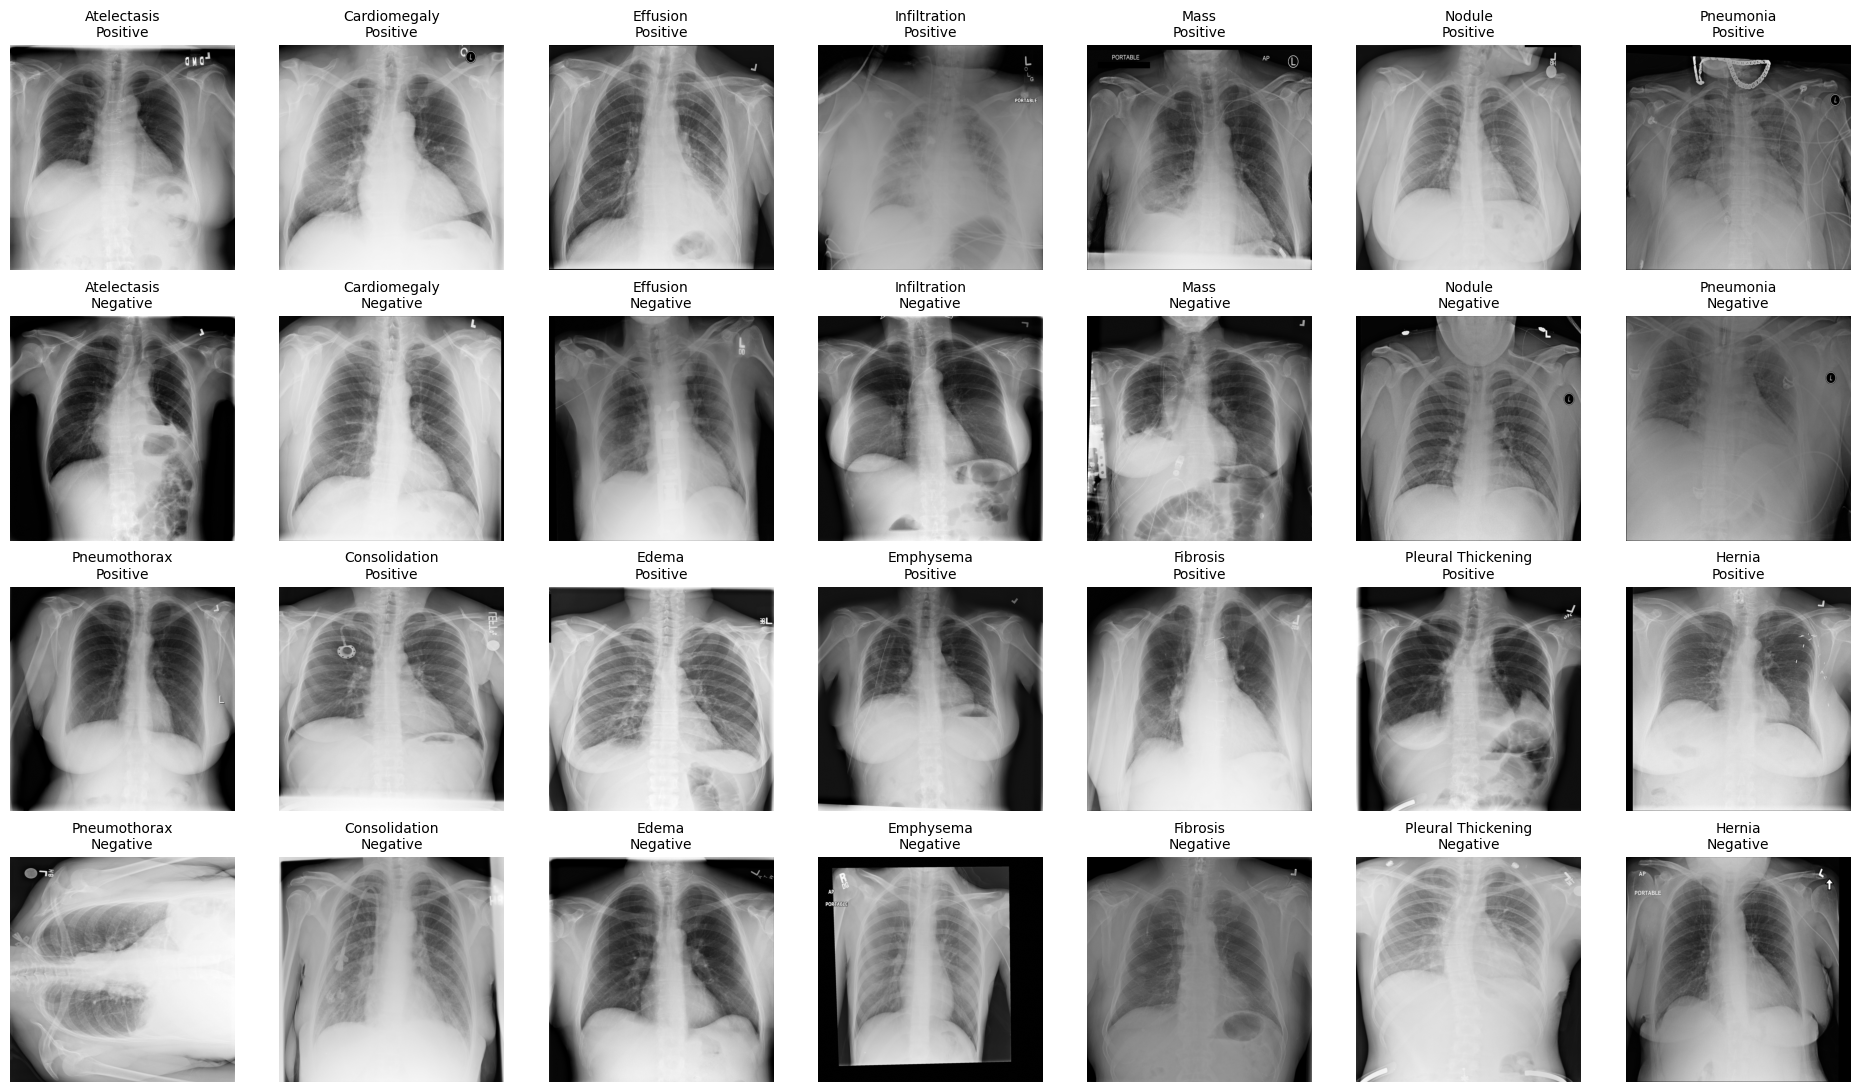

In [20]:
# Show positive and negative training examples for every finding
fig, axes = plt.subplots(4, 7, figsize=(19, 11))
for index, label in enumerate(LABELS):
    for offset, target in enumerate([1, 0]):
        row, column = (index // 7) * 2 + offset, index % 7
        ax = axes[row, column]
        examples = train_df[train_df[label] == target]
        if not examples.empty:
            sample = examples.sample(1, random_state=SEED).iloc[0]
            with Image.open(sample.image_path) as image:
                ax.imshow(image.convert('L'), cmap='gray')
        ax.set_title(label.replace('_', ' ') + '\n' + ('Positive' if target else 'Negative'), fontsize=10)
        ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [21]:
# Locate or download the verified public model checkpoints
import requests

HASHES = {
    'eva_x_small_patch16_merged520k_mim_cxr14_ft.pth':
        '86d7bf2864194316f7d70c8ac9fd1fef32a4584c3d94933c31a8f102a5e4383b',
    'eva_x_small_patch16_merged520k_mim.pt':
        '135d70a6988b5aacfe4848e1c2a0d524b2c076536fcaccdce88b636d302316c2',
}
def get_checkpoint(filename, explicit=''):
    if explicit and not Path(explicit).is_file():
        raise FileNotFoundError(f'Checkpoint path does not exist: {explicit}')
    attached = list(input_files(filename)) if not explicit else [Path(explicit)]
    destination = attached[0] if attached else WORK / 'eva_x_checkpoints' / filename
    if not destination.is_file():
        print('Downloading:', filename, flush=True)
        destination.parent.mkdir(exist_ok=True)
        temporary = destination.with_suffix(destination.suffix + '.part')
        url = f'https://huggingface.co/MapleF/eva_x/resolve/{HF_REVISION}/{filename}'
        with requests.get(url, stream=True, timeout=(20, 90)) as response:
            response.raise_for_status()
            with temporary.open('wb') as stream:
                for chunk in response.iter_content(8 * 1024 * 1024):
                    stream.write(chunk)
        temporary.replace(destination)
    if eva.sha256(destination) != HASHES[filename]:
        raise ValueError(f'Checkpoint checksum mismatch: {destination}')
    print('Verified:', filename)
    return str(destination)

reference_checkpoint = get_checkpoint(next(iter(HASHES)), TRAINED_WEIGHTS)
ssl_checkpoint = get_checkpoint('eva_x_small_patch16_merged520k_mim.pt', PRETRAINED_WEIGHTS) if RUN_TRAINING else ''


Downloading: eva_x_small_patch16_merged520k_mim_cxr14_ft.pth
Verified: eva_x_small_patch16_merged520k_mim_cxr14_ft.pth
Downloading: eva_x_small_patch16_merged520k_mim.pt
Verified: eva_x_small_patch16_merged520k_mim.pt


In [22]:
# Save the official training profile and Kaggle execution settings
cfg.update(epochs=EPOCHS, warmup_epochs=WARMUP_EPOCHS, eval_interval=EVAL_INTERVAL,
    learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, layer_decay=LAYER_DECAY,
    micro_batch=MICRO_BATCH, accumulation=ACCUMULATION, workers=NUM_WORKERS,
    eval_batch=EVAL_BATCH, world_size=GPU_COUNT, ssl_checkpoint=ssl_checkpoint,
    reference_checkpoint=reference_checkpoint, checkpoint_hashes=HASHES,
    split_hashes=SPLIT_HASHES, repo_commit=REPO_COMMIT, hf_revision=HF_REVISION,
    deadline_unix=RUN_STARTED + TIME_BUDGET_HOURS * 3600, resume=RESUME_TRAINING,
    run_training=RUN_TRAINING, label_order=LABELS, compatibility=compatibility,
    augmentation='official build_transform; rand-m6-mstd0.5-inc1; timm 0.9.16',
    selection_protocol='released official-test AUROC selection')
protocol = {
    'reference_macro_AUROC': 0.833,
    'benchmark': 'NIH ChestX-ray14 official test set; 14 findings; 25,596 images',
    'training': 'Full encoder and head; self-supervised initialization; 30 complete epochs',
    'splits': '75,312 train; 11,212 validation; 25,596 test; official released lists',
    'selection': 'Best official-test AUROC as in the release; test is used for selection and is not an independent estimate',
    'validation': 'The released NIH training recipe does not use val_official.txt',
    'evaluation_epochs': '1, 6, 11, 16, 21, 26, 30 by the upstream zero-based condition',
    'optimizer': 'AdamW; LR 0.001; five-epoch linear warm-up then fixed LR; layer decay 0.55; weight decay 0.05',
    'regularization': 'Drop path 0.2; RandAugment m6; no mixup, cutmix, or random erasing',
    'hardware': 'Two T4 GPUs and accumulation instead of four RTX 3090 GPUs; effective batch 1024',
    'numerics': 'PyTorch SDPA, packed SwiGLU and LayerNorm replace CUDA dependencies; timm 0.9.16 instead of 0.5.4',
    'threshold': 'Fixed 0.5 for supplementary binary metrics; no tuning on test labels',
    'resume': 'Optimizer, scaler and per-rank RNG saved after every epoch',
}
(RESULTS / 'config.json').write_text(json.dumps(cfg, indent=2))
(RESULTS / 'protocol.json').write_text(json.dumps(protocol, indent=2))
print(f'Fine-tuning: {RUN_TRAINING} | {EPOCHS} epochs | LR {LEARNING_RATE} | '
      f'warm-up {WARMUP_EPOCHS} | effective batch {MICRO_BATCH * GPU_COUNT * ACCUMULATION}')


Fine-tuning: True | 30 epochs | LR 0.001 | warm-up 5 | effective batch 1024


In [23]:
# Load the released NIH classifier with its trained 14-label head
device = torch.device('cuda:0')
load_start = time.perf_counter()
reference_model = eva.make_model(cfg, reference_checkpoint).to(device).eval()
eva.sync(device)
checkpoint_load_seconds = time.perf_counter() - load_start
print(f'Loaded official classifier: {sum(p.numel() for p in reference_model.parameters()):,} parameters')


Loaded official classifier: 21,672,590 parameters


In [24]:
# Evaluate the released classifier on the official NIH test images
truth, reference_probs, reference_loss, reference_seconds = eva.predict(
    reference_model, test_data, device, EVAL_BATCH, NUM_WORKERS)
reference_metrics = eva.save_evaluation(cfg, 'reference', test_data, truth,
                                        reference_probs, reference_loss, reference_seconds)
print(reference_metrics[['AUROC', 'AP', 'accuracy', 'precision', 'recall', 'F1']].round(3).to_string())
print(f'Released-checkpoint macro AUROC: {reference_metrics.AUROC.mean():.3f} '
      f'| published reference: 0.833 | inference: {reference_seconds:.1f}s')
del reference_model
gc.collect()
torch.cuda.empty_cache()


                    AUROC     AP  accuracy  precision  recall     F1
label                                                               
Atelectasis         0.795  0.373     0.870      0.487   0.210  0.294
Cardiomegaly        0.905  0.381     0.960      0.573   0.184  0.279
Effusion            0.845  0.549     0.844      0.593   0.460  0.518
Infiltration        0.714  0.418     0.751      0.468   0.322  0.382
Mass                0.845  0.362     0.934      0.537   0.209  0.301
Nodule              0.766  0.227     0.935      0.433   0.071  0.123
Pneumonia           0.752  0.065     0.978      0.000   0.000  0.000
Pneumothorax        0.886  0.473     0.902      0.633   0.130  0.215
Consolidation       0.773  0.191     0.928      0.273   0.008  0.016
Edema               0.861  0.205     0.962      0.346   0.061  0.103
Emphysema           0.930  0.436     0.960      0.570   0.241  0.338
Fibrosis            0.852  0.135     0.983      0.667   0.014  0.027
Pleural_Thickening  0.797  0.164  

In [25]:
%%writefile {WORK / 'eva_x_nih_train.py'}
# Start the training worker with the saved configuration
import json
import sys
from eva_x_nih_runtime import run_training

if __name__ == '__main__':
    with open(sys.argv[1]) as stream:
        run_training(json.load(stream))


Writing /kaggle/working/eva_x_nih_train.py


In [26]:
# Fine-tune the complete encoder and head using the released training profile
worker_file = WORK / 'eva_x_nih_train.py'
training_wall_seconds = 0.
setup_and_reference_seconds = time.time() - RUN_STARTED
if RUN_TRAINING:
    print('Training follows the official NIH recipe and test-AUROC selection.', flush=True)
    train_start = time.perf_counter()
    environment = os.environ.copy()
    environment['OMP_NUM_THREADS'] = '1'
    environment['PYTHONUNBUFFERED'] = '1'
    import socket
    with socket.socket() as listener:
        listener.bind(('127.0.0.1', 0))
        port = listener.getsockname()[1]
    command = [sys.executable, '-m', 'torch.distributed.run', '--nnodes=1',
               '--master_addr=127.0.0.1', f'--master_port={port}',
               f'--nproc_per_node={GPU_COUNT}', str(worker_file), str(RESULTS / 'config.json')]
    with (RESULTS / 'training.log').open('a', buffering=1) as log:
        process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1, env=environment, cwd=WORK)
        for line in process.stdout:
            print(line, end='', flush=True)
            log.write(line)
        return_code = process.wait()
    training_wall_seconds = time.perf_counter() - train_start
    if return_code:
        raise RuntimeError('Fine-tuning failed; inspect training.log before continuing.')
else:
    print('Evaluation-only run; no training curves will be generated.')


Training follows the official NIH recipe and test-AUROC selection.
/kaggle/working/eva_x_nih_official/models_eva.py:797: UserWarning: Overwriting eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE in registry with eva_x_nih_official.models_eva.eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
/kaggle/working/eva_x_nih_official/models_eva.py:797: UserWarning: Overwriting eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE in registry with eva_x_nih_official.models_eva.eva02_base_patch16_xattn_fusedLN_NaiveSwiGLU_subln_RoPE. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  @register_model
Training 21,672,590 parameters on 2 device(s).
Training images: 75,312 | effective batch: 1,024
Checkpoint selection follows the released official-test AUROC protocol.
First optimizer step comp

In [27]:
# Evaluate our best fine-tuned model separately from the released classifier
selected_name = 'reference'
selected_probs = reference_probs
selected_metrics = reference_metrics
if RUN_TRAINING:
    own_checkpoint = RESULTS / 'finetuned' / 'best.pth'
    if not own_checkpoint.is_file():
        raise FileNotFoundError('No fine-tuned checkpoint was saved.')
    model = eva.make_model(cfg, own_checkpoint).to(device).eval()
    own_truth, selected_probs, own_loss, own_seconds = eva.predict(
        model, test_data, device, EVAL_BATCH, NUM_WORKERS)
    if not np.array_equal(truth, own_truth):
        raise ValueError('Evaluation row order changed between the two models.')
    selected_name = 'finetuned'
    selected_metrics = eva.save_evaluation(cfg, selected_name, test_data, truth,
                                          selected_probs, own_loss, own_seconds)
    print(selected_metrics[['AUROC', 'AP', 'accuracy', 'precision', 'recall', 'F1']].round(3).to_string())
    print(f'Our fine-tuned macro AUROC: {selected_metrics.AUROC.mean():.3f}')
    del model
    gc.collect()
    torch.cuda.empty_cache()
PLOTS = RESULTS / selected_name


                    AUROC     AP  accuracy  precision  recall     F1
label                                                               
Atelectasis         0.791  0.374     0.874      0.528   0.170  0.257
Cardiomegaly        0.902  0.385     0.961      0.601   0.230  0.333
Effusion            0.848  0.550     0.846      0.599   0.465  0.524
Infiltration        0.720  0.421     0.757      0.483   0.240  0.320
Mass                0.839  0.357     0.934      0.532   0.216  0.307
Nodule              0.750  0.216     0.936      0.483   0.051  0.092
Pneumonia           0.740  0.055     0.978      0.000   0.000  0.000
Pneumothorax        0.884  0.444     0.896      0.557   0.020  0.039
Consolidation       0.771  0.186     0.929      0.000   0.000  0.000
Edema               0.862  0.213     0.964      0.526   0.011  0.021
Emphysema           0.924  0.438     0.960      0.583   0.243  0.343
Fibrosis            0.838  0.106     0.983      0.000   0.000  0.000
Pleural_Thickening  0.790  0.150  

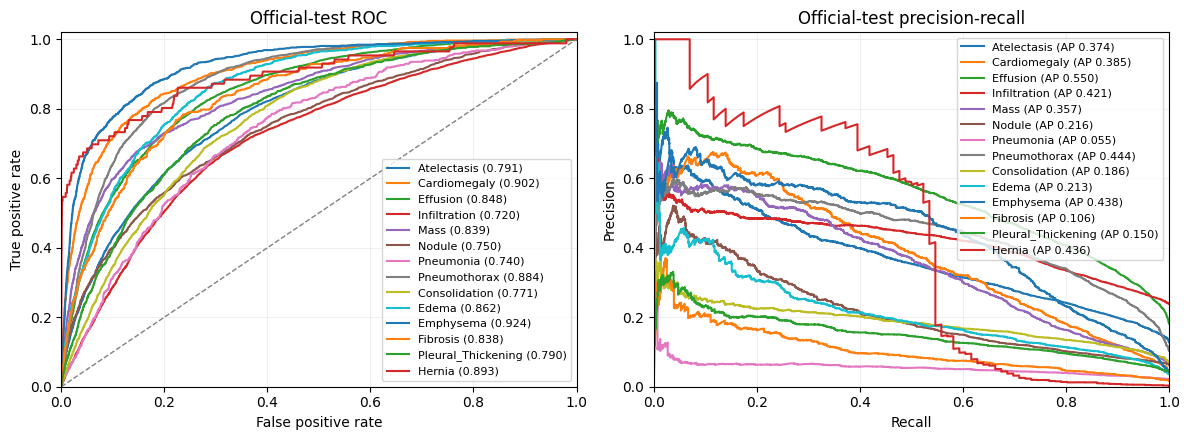

In [28]:
# Plot the official-test ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for i, label in enumerate(LABELS):
    if len(np.unique(truth[:, i])) == 2:
        fpr, tpr, _ = roc_curve(truth[:, i], selected_probs[:, i])
        axes[0].plot(fpr, tpr, label=f'{label} ({selected_metrics.loc[label, "AUROC"]:.3f})')
    if truth[:, i].sum():
        precision, recall, _ = precision_recall_curve(truth[:, i], selected_probs[:, i])
        axes[1].plot(recall, precision, label=f'{label} (AP {selected_metrics.loc[label, "AP"]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Official-test ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Official-test precision-recall')
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(PLOTS / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


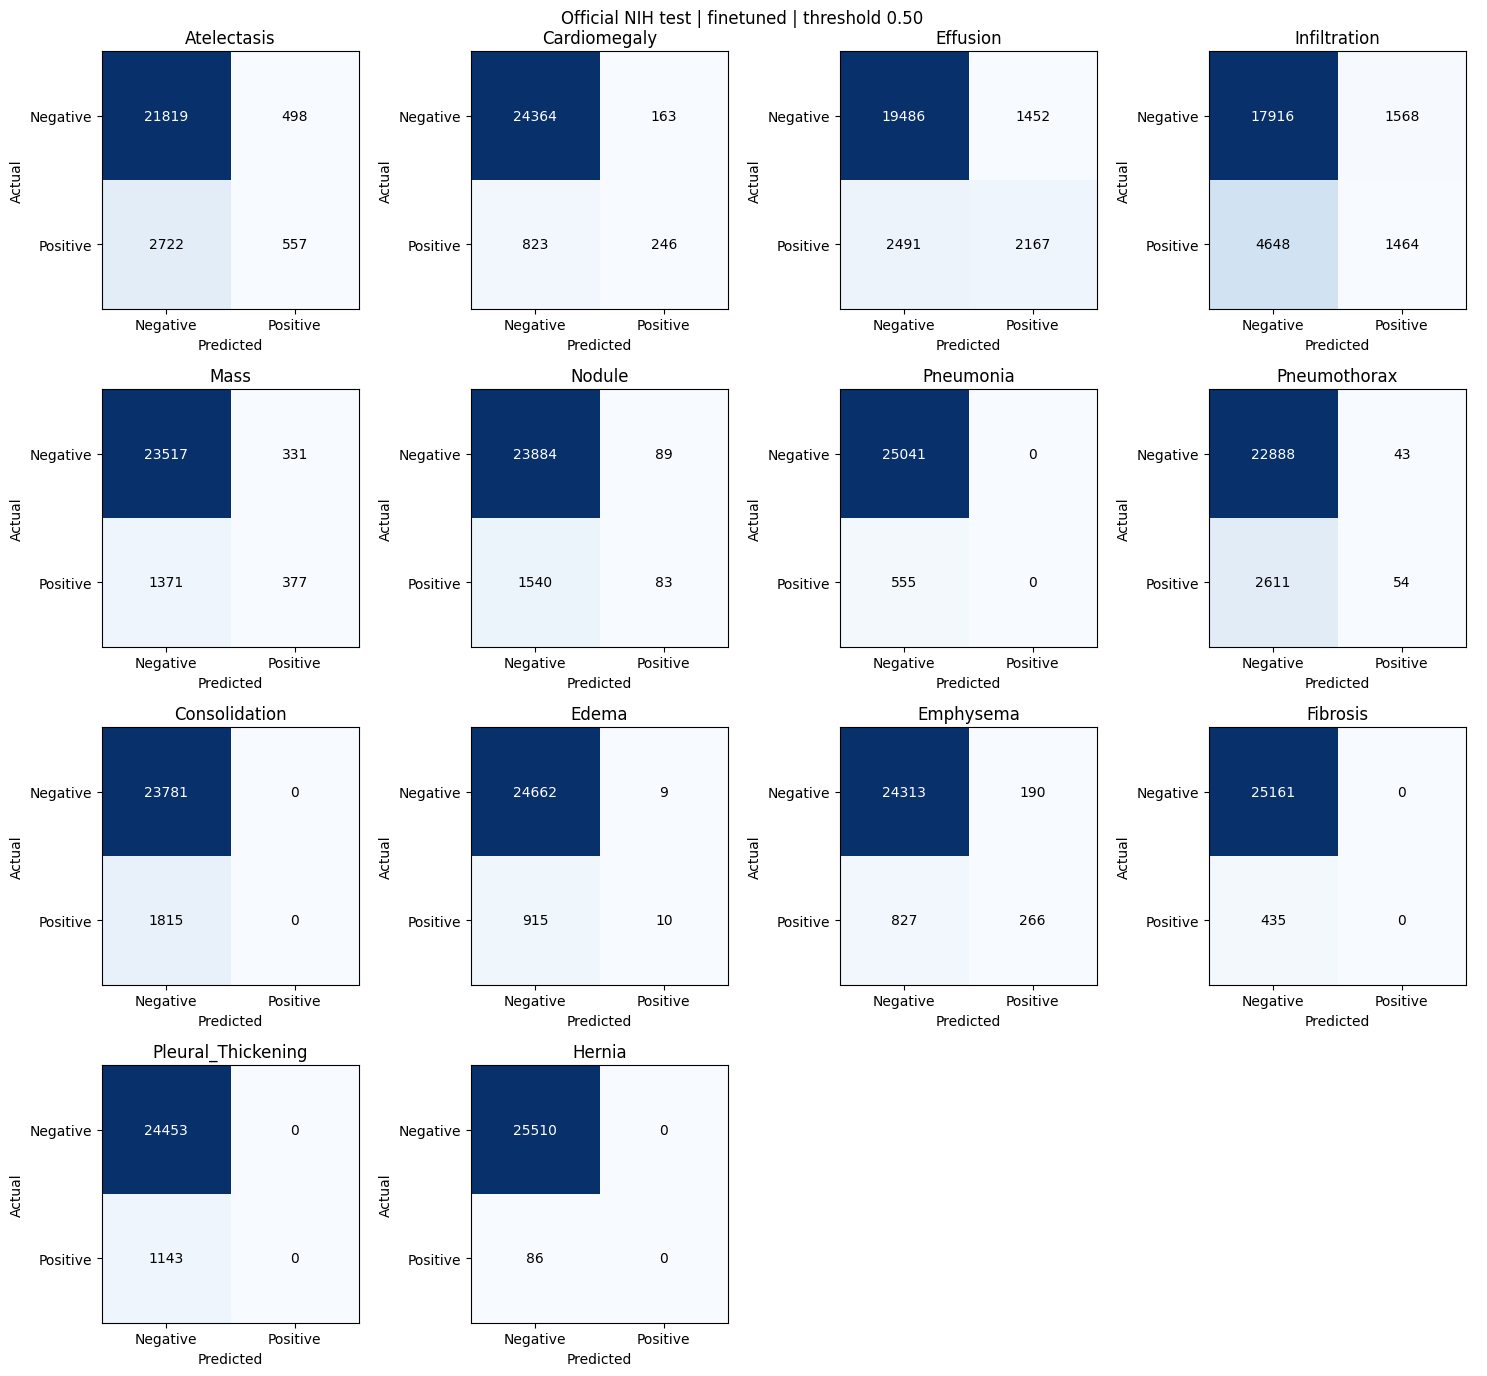

In [29]:
# Plot the 14 confusion matrices
fig, axes = plt.subplots(4, 4, figsize=(15, 14))
for i, label in enumerate(LABELS):
    matrix = confusion_matrix(truth[:, i], selected_probs[:, i] >= THRESHOLD, labels=[0, 1])
    ax = axes.flat[i]
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            color = 'white' if matrix[row, column] > matrix.max() / 2 else 'black'
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center', color=color)
    ax.set(title=label, xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1],
           xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
for ax in axes.flat[len(LABELS):]:
    ax.axis('off')
fig.suptitle(f'Official NIH test | {selected_name} | threshold {THRESHOLD:.2f}')
fig.tight_layout()
fig.savefig(PLOTS / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


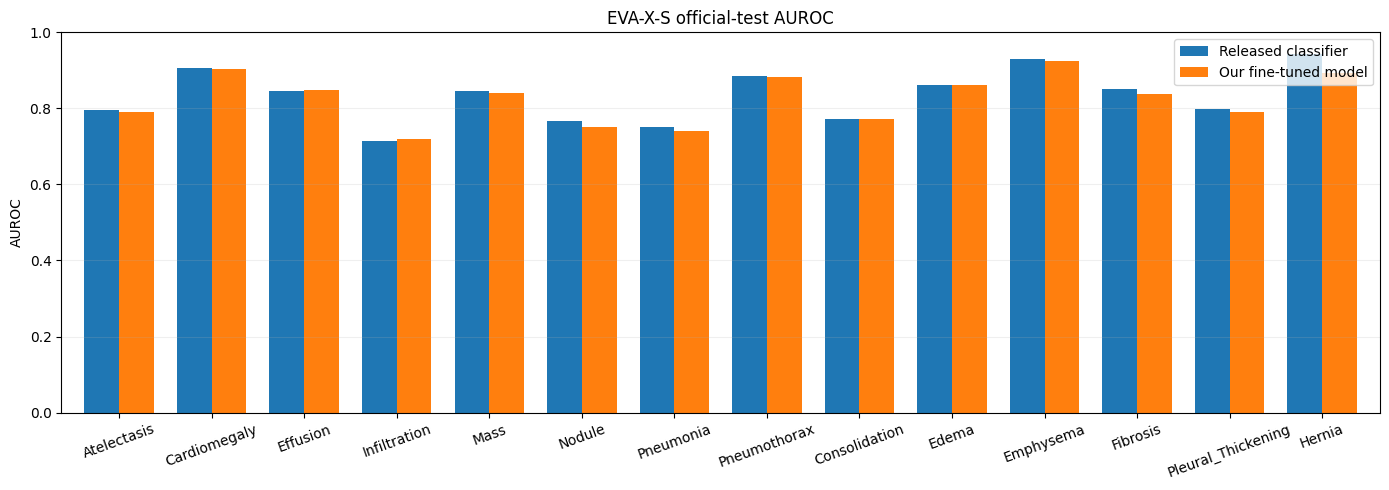

In [30]:
# Compare class-wise AUROC for the two evaluated checkpoints
comparison = pd.DataFrame({'Released classifier': reference_metrics.AUROC})
if RUN_TRAINING:
    comparison['Our fine-tuned model'] = selected_metrics.AUROC
ax = comparison.plot.bar(figsize=(14, 5), ylim=(0, 1), rot=20, width=0.75)
ax.set(title='EVA-X-S official-test AUROC', xlabel='', ylabel='AUROC')
ax.grid(axis='y', alpha=0.2)
ax.figure.tight_layout()
ax.figure.savefig(RESULTS / 'class_auroc.png', dpi=180)
plt.show()
plt.close(ax.figure)


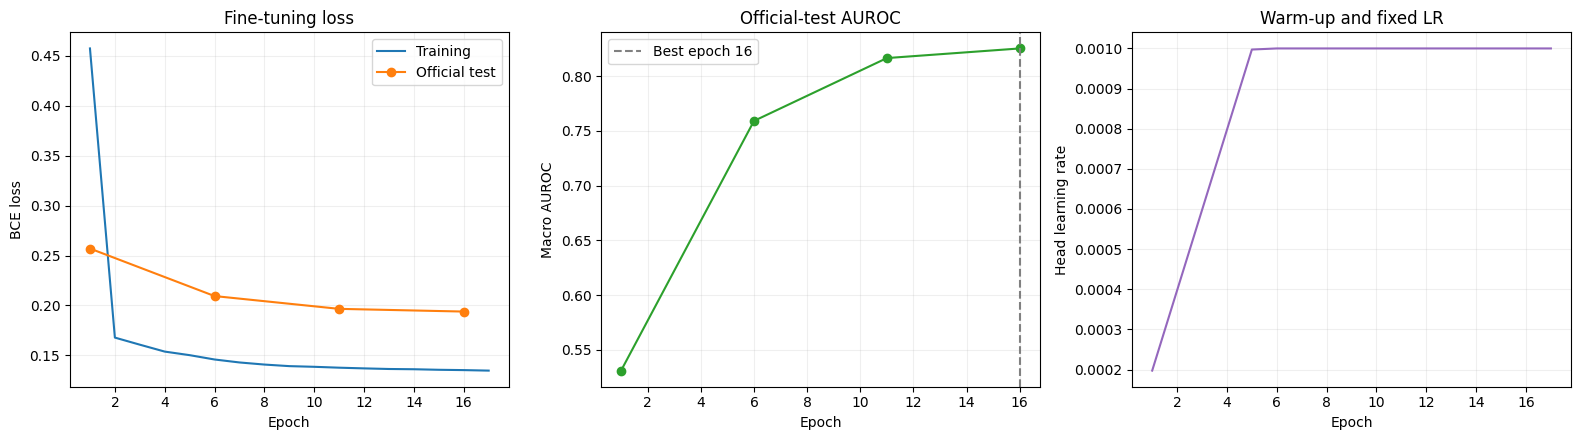

In [31]:
# Plot training loss, scheduled test metrics, and the warm-up learning rate
if RUN_TRAINING:
    history = pd.read_csv(RESULTS / 'finetuned' / 'history.csv')
    evaluated = history.dropna(subset=['test_AUROC'])
    best_epoch = int(evaluated.loc[evaluated.test_AUROC.idxmax(), 'epoch'])
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(history.epoch, history.train_loss, label='Training')
    axes[0].plot(evaluated.epoch, evaluated.test_loss, 'o-', label='Official test')
    axes[0].set(xlabel='Epoch', ylabel='BCE loss', title='Fine-tuning loss')
    axes[0].legend()
    axes[1].plot(evaluated.epoch, evaluated.test_AUROC, 'o-', color='tab:green')
    axes[1].axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch {best_epoch}')
    axes[1].set(xlabel='Epoch', ylabel='Macro AUROC', title='Official-test AUROC')
    axes[1].legend()
    axes[2].plot(history.epoch, history.learning_rate, color='tab:purple')
    axes[2].set(xlabel='Epoch', ylabel='Head learning rate', title='Warm-up and fixed LR')
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(RESULTS / 'finetuned' / 'learning_curves.png', dpi=180)
    plt.show()
    plt.close(fig)


In [32]:
# Save the timing, software versions, and source references
timing = dict(setup_and_reference_seconds=setup_and_reference_seconds,
              checkpoint_load_seconds=checkpoint_load_seconds, reference_inference_seconds=reference_seconds,
              training_stage_wall_seconds=training_wall_seconds, total_wall_seconds=time.time()-RUN_STARTED)
if RUN_TRAINING:
    timing.update(json.loads((RESULTS / 'finetuned' / 'training_summary.json').read_text()))
(RESULTS / 'timing.json').write_text(json.dumps(timing, indent=2))
versions = {name: metadata.version(name) for name in ['torch', 'torchvision', 'timm', 'einops',
             'pandas', 'numpy', 'scikit-learn', 'huggingface_hub']}
versions['GPUs'] = [torch.cuda.get_device_name(i) for i in range(GPU_COUNT)]
(RESULTS / 'environment.json').write_text(json.dumps(versions, indent=2))
sources = [
    'https://www.nature.com/articles/s41746-025-02032-z',
    f'https://github.com/hustvl/EVA-X/tree/{REPO_COMMIT}',
    f'https://huggingface.co/MapleF/eva_x/tree/{HF_REVISION}',
]
(RESULTS / 'sources.txt').write_text('\n'.join(sources) + '\n')
(RESULTS / 'README.md').write_text(
    'EVA-X-S on NIH ChestX-ray14\n\nReference metrics evaluate the released classifier. '
    'Finetuned metrics evaluate our full encoder/head run, if enabled. '
    'Both use the official NIH test set; our checkpoint selection follows the released test-AUROC procedure. See config.json, protocol.json, '
    'environment.json, timing.json and sources.txt for reproduction details. '
    'Training duration is recorded in complete epochs.\n')
print(f'Total elapsed: {timing["total_wall_seconds"]/60:.1f} minutes')
print('Saved results:', RESULTS)

Total elapsed: 286.1 minutes
Saved results: /kaggle/working/eva_x_s_nih_results/seed0
